In [ ]:
# ==============================================================================
# DATASET : Indonesia Hourly Weather for Rain Prediction (Cuaca & Prediksi Hujan)
# SUMBER  : Kaggle (karanroyka/indonesia-hourly-weather-for-rain-prediction)
# VARIABEL: df_weather
# ==============================================================================

import os
import kagglehub
from kagglehub import KaggleDatasetAdapter

dataset_handle_weather = "karanroyka/indonesia-hourly-weather-for-rain-prediction"
dataset_dir_weather = kagglehub.dataset_download(dataset_handle_weather)

supported_exts = ('.csv', '.tsv', '.json', '.jsonl', '.parquet', '.feather', '.xls', '.xlsx')
found_files_weather = [
    os.path.relpath(os.path.join(root, f), dataset_dir_weather)
    for root, _, files in os.walk(dataset_dir_weather)
    for f in files if f.lower().endswith(supported_exts)
]

if found_files_weather:
    file_path_weather = found_files_weather[0]
    nama_file_weather = os.path.basename(file_path_weather)

    df_weather = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        dataset_handle_weather,
        file_path_weather,
    )
    print(f"{nama_file_weather} berhasil terekspor")
else:
    print("File tidak ditemukan. Isi folder:", os.listdir(dataset_dir_weather))

Using Colab cache for faster access to the 'indonesia-hourly-weather-for-rain-prediction' dataset.
Using Colab cache for faster access to the 'indonesia-hourly-weather-for-rain-prediction' dataset.
ml_dataset.csv berhasil terekspor


In [ ]:
# ==============================================================================
# DATASET : Sea Water Level in Indonesia (Ketinggian Air Laut Indonesia)
# SUMBER  : Kaggle (jalaludinmuflih/dataset-sea-water-level-in-indonesia)
# VARIABEL: df_sea
# ==============================================================================

import os
import kagglehub
from kagglehub import KaggleDatasetAdapter

dataset_handle_sea = "jalaludinmuflih/dataset-sea-water-level-in-indonesia"
dataset_dir_sea = kagglehub.dataset_download(dataset_handle_sea)

supported_exts = ('.csv', '.tsv', '.json', '.jsonl', '.parquet', '.feather', '.xls', '.xlsx')
found_files_sea = [
    os.path.relpath(os.path.join(root, f), dataset_dir_sea)
    for root, _, files in os.walk(dataset_dir_sea)
    for f in files if f.lower().endswith(supported_exts)
]

if found_files_sea:
    file_path_sea = found_files_sea[0]
    nama_file_sea = os.path.basename(file_path_sea)

    df_sea = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        dataset_handle_sea,
        file_path_sea,
    )
    print(f"{nama_file_sea} berhasil terekspor")
else:
    print("File tidak ditemukan. Isi folder:", os.listdir(dataset_dir_sea))

Using Colab cache for faster access to the 'dataset-sea-water-level-in-indonesia' dataset.
Using Colab cache for faster access to the 'dataset-sea-water-level-in-indonesia' dataset.
Dataset Sea Watel level in indonesia.xlsx berhasil terekspor


In [ ]:
# ==============================================================================
# DATASET : Banjir Jabodetabek
# SUMBER  : Kaggle (yusufginanjar7/banjir-jabodetabek)
# VARIABEL: df_banjir
# ==============================================================================

import os
import kagglehub
from kagglehub import KaggleDatasetAdapter

dataset_handle_banjir = "yusufginanjar7/banjir-jabodetabek"
dataset_dir_banjir = kagglehub.dataset_download(dataset_handle_banjir)

supported_exts = ('.csv', '.tsv', '.json', '.jsonl', '.parquet', '.feather', '.xls', '.xlsx')
found_files_banjir = [
    os.path.relpath(os.path.join(root, f), dataset_dir_banjir)
    for root, _, files in os.walk(dataset_dir_banjir)
    for f in files if f.lower().endswith(supported_exts)
]

if found_files_banjir:
    file_path_banjir = found_files_banjir[0]
    nama_file_banjir = os.path.basename(file_path_banjir)

    df_banjir = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        dataset_handle_banjir,
        file_path_banjir,
    )
    print(f"{nama_file_banjir} berhasil terekspor")
else:
    print("File tidak ditemukan. Isi folder:", os.listdir(dataset_dir_banjir))



Using Colab cache for faster access to the 'banjir-jabodetabek' dataset.
Using Colab cache for faster access to the 'banjir-jabodetabek' dataset.
data_banjir_combine_final.csv berhasil terekspor


In [ ]:
# ==============================================================================
# TAHAP ETL 1 : INSPEKSI SKEMA, RENTANG WAKTU, & NILAI LOKASI (DATA PROFILING)
# TUJUAN      : Mengecek nama kolom, tipe data, rentang tanggal, dan daftar lokasi
#               dengan alias tampilan yang informatif untuk NAME_2 & NAME_3
# INPUT       : df_weather, df_sea, df_banjir
# ==============================================================================

import pandas as pd
from IPython.display import display, HTML

# Definisi fungsi global tampilkan_rapi di sel paling awal agar siap dipakai di seluruh notebook
def tampilkan_rapi(df, max_rows=None, max_height="600px", judul=None):
    """
    Menampilkan DataFrame dengan layout lebar alami (memanjang ke kanan):
    - Sticky header (atas) & sticky kolom index (kiri)
    - Tidak ada angka atau nama kolom yang terpotong/patah ke bawah
    - Kolom teks panjang ('alasan_kategori', dll.) otomatis diberi ruang lebar & wrap rapi
    """
    df_view = df.head(max_rows).copy() if max_rows else df.copy()

    # Bulatkan kolom float menjadi 2 angka di belakang koma
    float_cols = df_view.select_dtypes(include=['float64', 'float32']).columns
    for col in float_cols:
        df_view[col] = df_view[col].round(2)

    html_table = df_view.to_html(classes="wide-clean-table", border=0, na_rep="-")

    label_judul = f"<b>{judul}</b> — " if judul else ""
    info_baris = (
        f"{label_judul}Menampilkan {len(df_view):,} dari total {len(df):,} baris"
        if max_rows and len(df) > max_rows
        else f"{label_judul}Menampilkan SELURUH data: {len(df):,} baris × {len(df.columns)} kolom"
    )

    # Aturan tambahan khusus jika kolom terakhir adalah kolom keterangan/alasan panjang
    kolom_terakhir = str(df_view.columns[-1]).lower() if len(df_view.columns) > 0 else ""
    css_last_col = """
        .wide-clean-table td:last-child {
            white-space: normal;
            min-width: 380px;
            max-width: 520px;
            line-height: 1.5;
        }
    """ if any(k in kolom_terakhir for k in ['alasan', 'keterangan', 'deskripsi', 'catatan']) else ""

    custom_html = f"""
    <style>
        .table-meta {{
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            font-weight: 500;
            color: #cbd5e1;
            margin-top: 12px;
            margin-bottom: 6px;
        }}
        .table-wrapper {{
            max-height: {max_height};
            max-width: 100%;
            overflow: auto;
            border: 1px solid #334155;
            border-radius: 8px;
            box-shadow: 0 4px 12px rgba(0, 0, 0, 0.3);
            background-color: #0f172a;
        }}
        .wide-clean-table {{
            width: max-content;
            border-collapse: separate;
            border-spacing: 0;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            color: #e2e8f0;
        }}
        .wide-clean-table th,
        .wide-clean-table td {{
            padding: 10px 16px;
            border-bottom: 1px solid #1e293b;
            border-right: 1px solid #1e293b;
            text-align: left;
            white-space: nowrap;
            vertical-align: middle;
        }}
        {css_last_col}
        /* Sticky Header Atas */
        .wide-clean-table thead th {{
            position: sticky;
            top: 0;
            background-color: #1e293b;
            color: #f8fafc;
            font-weight: 600;
            text-transform: uppercase;
            font-size: 11.5px;
            letter-spacing: 0.05em;
            z-index: 10;
            border-bottom: 2px solid #475569;
            padding: 12px 16px;
        }}
        /* Sticky Kolom Index (Kiri) */
        .wide-clean-table tbody th {{
            position: sticky;
            left: 0;
            background-color: #0f172a;
            color: #94a3b8;
            font-weight: 600;
            z-index: 5;
            border-right: 2px solid #334155;
        }}
        .wide-clean-table thead th:first-child {{
            left: 0;
            z-index: 15;
            border-right: 2px solid #334155;
        }}
        /* Zebra striping & hover */
        .wide-clean-table tbody tr:nth-child(even) td {{
            background-color: #131c31;
        }}
        .wide-clean-table tbody tr:hover td {{
            background-color: #1e3a5f;
        }}
    </style>
    <div class="table-meta">{info_baris}</div>
    <div class="table-wrapper">
        {html_table}
    </div>
    """
    display(HTML(custom_html))

# Mapping tampilan sementara agar pembaca tahu nama asli sekaligus artinya
alias_kolom = {
    'NAME_2': 'kabupaten_kota (NAME_2)',
    'NAME_3': 'kecamatan (NAME_3)'
}

datasets = {
    "A - Hourly Weather (df_weather)": df_weather,
    "B - Sea Water Level (df_sea)": df_sea,
    "C - Banjir Jabodetabek (df_banjir)": df_banjir.rename(columns=alias_kolom)
}

for nama, data in datasets.items():
    print("=" * 80)
    print(f"DATASET : {nama} | Dimensi: {data.shape}")
    print("KOLOM   :", list(data.columns))
    print("\nTIPE DATA:")
    print(data.dtypes)

    # Mencari kolom yang berpotensi berisi informasi lokasi/kota/stasiun/kejadian
    for col in data.columns:
        if data[col].dtype == 'object' and data[col].nunique() <= 50:
            print(f"\nNilai Unik [{col}] ({data[col].nunique()} unik):")
            print(data[col].dropna().unique()[:20])

    # Menampilkan contoh 3 baris pertama dengan tampilan rapi
    tampilkan_rapi(data, max_rows=3, max_height="300px", judul=f"Contoh Data {nama}")

DATASET : A - Hourly Weather (df_weather) | Dimensi: (210384, 15)
KOLOM   : ['temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'surface_pressure', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'precipitation', 'rain', 'city', 'latitude', 'longitude', 'timestamp', 'rain_sum_next_6h', 'rain_next_6h']

TIPE DATA:
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
surface_pressure        float64
cloud_cover               int64
wind_speed_10m          float64
wind_direction_10m        int64
precipitation           float64
rain                    float64
city                     object
latitude                float64
longitude               float64
timestamp                object
rain_sum_next_6h        float64
rain_next_6h              int64
dtype: object

Nilai Unik [city] (8 unik):
['Bandung' 'Denpasar' 'Jakarta' 'Makassar' 'Medan' 'Semarang' 'Surabaya'
 'Yogyakarta']


,temperature_2m,relative_humidity_2m,apparent_temperature,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,precipitation,rain,city,latitude,longitude,timestamp,rain_sum_next_6h,rain_next_6h
0,19.8,82,20.9,932.4,100,7.4,331,0.0,0.0,Bandung,-6.92,107.62,2022-01-01 05:00:00,0.1,1
1,18.9,89,20.4,932.8,100,6.4,322,0.0,0.0,Bandung,-6.92,107.62,2022-01-01 06:00:00,0.0,0
2,21.6,78,23.9,933.8,100,3.6,323,0.0,0.0,Bandung,-6.92,107.62,2022-01-01 07:00:00,0.0,0


DATASET : B - Sea Water Level (df_sea) | Dimensi: (505, 6)
KOLOM   : ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']

TIPE DATA:
Unnamed: 0    float64
Unnamed: 1    float64
Unnamed: 2    float64
Unnamed: 3     object
Unnamed: 4     object
Unnamed: 5     object
dtype: object

Nilai Unik [Unnamed: 3] (4 unik):
['Dataset Kenaikan air laut di indonesia' 'Negara' 'Indonesian'
 'Catatan: pengambilan data di ambil dengan rentang waktu  setiap ±10 hari sekali']


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,-,-,-,Dataset Kenaikan air laut di indonesia,-,-
1,-,-,-,-,-,-
2,-,-,-,Negara,Date,Value


DATASET : C - Banjir Jabodetabek (df_banjir) | Dimensi: (18047, 17)
KOLOM   : ['kabupaten_kota (NAME_2)', 'kecamatan (NAME_3)', 'avg_rainfall', 'max_rainfall', 'avg_temperature', 'elevation', 'landcover_class', 'ndvi', 'slope', 'soil_moisture', 'year', 'month', 'banjir', 'lat', 'long', 'map_image', 'NAME_3_clean']

TIPE DATA:
kabupaten_kota (NAME_2)     object
kecamatan (NAME_3)          object
avg_rainfall               float64
max_rainfall               float64
avg_temperature            float64
elevation                  float64
landcover_class             object
ndvi                       float64
slope                      float64
soil_moisture              float64
year                         int64
month                        int64
banjir                       int64
lat                        float64
long                       float64
map_image                   object
NAME_3_clean                object
dtype: object

Nilai Unik [landcover_class] (11 unik):
['Tree cover' 'Built-u

,kabupaten_kota (NAME_2),kecamatan (NAME_3),avg_rainfall,max_rainfall,avg_temperature,elevation,landcover_class,ndvi,slope,soil_moisture,year,month,banjir,lat,long,map_image,NAME_3_clean
0,bogor,babakanmadang,64.78,124.03,28.76,501.91,Tree cover,0.56,5.00,39.58,2020,1,1,-6.59,106.90,RGB_BabakanMadang2020.tif,babakanmadang
1,bogor,bojonggede,68.24,128.95,32.89,133.59,Built-up,0.43,0.29,40.41,2020,1,1,-6.48,106.79,RGB_BabakanMadang2020.tif,bojonggede
2,bogor,caringin,56.42,92.32,29.93,765.65,Tree cover,0.51,4.95,39.66,2020,1,0,-6.74,106.87,RGB_Caringin2020(2).tif,caringin


In [ ]:
# ==============================================================================
# TAHAP ETL 2 : TRANSFORMASI DATASET A (HOURLY WEATHER -> MONTHLY JAKARTA)
# TUJUAN      : Menyaring cuaca wilayah Jakarta dan mengagregasinya ke skala
#               bulanan (year, month) agar selaras dengan resolusi Dataset C
# INPUT       : df_weather
# OUTPUT      : df_weather_monthly
# ==============================================================================

import pandas as pd
from IPython.display import display, HTML

# Definisi fungsi global tampilkan_rapi agar siap dipakai sejak tahap ETL 2 hingga akhir
def tampilkan_rapi(df, max_rows=None, max_height="600px", judul=None):
    """
    Menampilkan DataFrame dengan layout lebar alami (memanjang ke kanan):
    - Sticky header (atas) & sticky kolom index (kiri)
    - Tidak ada angka atau nama kolom yang terpotong/patah ke bawah
    - Kolom teks panjang ('alasan_kategori', dll.) otomatis diberi ruang lebar & wrap rapi
    """
    df_view = df.head(max_rows).copy() if max_rows else df.copy()

    # Bulatkan kolom float menjadi 2 angka di belakang koma
    float_cols = df_view.select_dtypes(include=['float64', 'float32']).columns
    for col in float_cols:
        df_view[col] = df_view[col].round(2)

    html_table = df_view.to_html(classes="wide-clean-table", border=0, na_rep="-")

    label_judul = f"<b>{judul}</b> — " if judul else ""
    info_baris = (
        f"{label_judul}Menampilkan {len(df_view):,} dari total {len(df):,} baris"
        if max_rows and len(df) > max_rows
        else f"{label_judul}Menampilkan SELURUH data: {len(df):,} baris × {len(df.columns)} kolom"
    )

    # Aturan tambahan khusus jika kolom terakhir adalah kolom keterangan/alasan panjang
    kolom_terakhir = str(df_view.columns[-1]).lower() if len(df_view.columns) > 0 else ""
    css_last_col = """
        .wide-clean-table td:last-child {
            white-space: normal;
            min-width: 380px;
            max-width: 520px;
            line-height: 1.5;
        }
    """ if any(k in kolom_terakhir for k in ['alasan', 'keterangan', 'deskripsi', 'catatan']) else ""

    custom_html = f"""
    <style>
        .table-meta {{
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            font-weight: 500;
            color: #cbd5e1;
            margin-top: 12px;
            margin-bottom: 6px;
        }}
        .table-wrapper {{
            max-height: {max_height};
            max-width: 100%;
            overflow: auto;
            border: 1px solid #334155;
            border-radius: 8px;
            box-shadow: 0 4px 12px rgba(0, 0, 0, 0.3);
            background-color: #0f172a;
        }}
        .wide-clean-table {{
            width: max-content;
            border-collapse: separate;
            border-spacing: 0;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            color: #e2e8f0;
        }}
        .wide-clean-table th,
        .wide-clean-table td {{
            padding: 10px 16px;
            border-bottom: 1px solid #1e293b;
            border-right: 1px solid #1e293b;
            text-align: left;
            white-space: nowrap;
            vertical-align: middle;
        }}
        {css_last_col}
        /* Sticky Header Atas */
        .wide-clean-table thead th {{
            position: sticky;
            top: 0;
            background-color: #1e293b;
            color: #f8fafc;
            font-weight: 600;
            text-transform: uppercase;
            font-size: 11.5px;
            letter-spacing: 0.05em;
            z-index: 10;
            border-bottom: 2px solid #475569;
            padding: 12px 16px;
        }}
        /* Sticky Kolom Index (Kiri) */
        .wide-clean-table tbody th {{
            position: sticky;
            left: 0;
            background-color: #0f172a;
            color: #94a3b8;
            font-weight: 600;
            z-index: 5;
            border-right: 2px solid #334155;
        }}
        .wide-clean-table thead th:first-child {{
            left: 0;
            z-index: 15;
            border-right: 2px solid #334155;
        }}
        /* Zebra striping & hover */
        .wide-clean-table tbody tr:nth-child(even) td {{
            background-color: #131c31;
        }}
        .wide-clean-table tbody tr:hover td {{
            background-color: #1e3a5f;
        }}
    </style>
    <div class="table-meta">{info_baris}</div>
    <div class="table-wrapper">
        {html_table}
    </div>
    """
    display(HTML(custom_html))

df_w = df_weather.copy()

# 1. Filter Khusus Wilayah Jakarta (Mewakili Pesisir Jabodetabek pada Dataset A)
df_w = df_w[df_w['city'] == 'Jakarta'].copy()

# 2. Ekstraksi Tahun & Bulan dari kolom 'timestamp'
df_w['timestamp'] = pd.to_datetime(df_w['timestamp'])
df_w['year'] = df_w['timestamp'].dt.year
df_w['month'] = df_w['timestamp'].dt.month

# 3. Agregasi Fitur Cuaca ke Skala Bulanan (year, month)
df_weather_monthly = df_w.groupby(['year', 'month']).agg(
    weather_rain_sum=('rain', 'sum'),                   # Total curah hujan bulanan (mm)
    weather_rain_max=('rain', 'max'),                   # Intensitas hujan puncak per jam dalam sebulan
    weather_precip_sum=('precipitation', 'sum'),        # Total presipitasi bulanan
    weather_humidity_mean=('relative_humidity_2m', 'mean'),
    weather_temp_mean=('temperature_2m', 'mean'),
    weather_wind_max=('wind_speed_10m', 'max'),
    weather_pressure_mean=('surface_pressure', 'mean')
).reset_index()

print("=" * 70)
print(f"✅ Transformasi Dataset A selesai. Dimensi baru: {df_weather_monthly.shape}")
print(f"Rentang Waktu: {df_weather_monthly['year'].min()}-{df_weather_monthly['month'].min()} s/d {df_weather_monthly['year'].max()}-{df_weather_monthly['month'].max()}")
print("=" * 70)

# Menampilkan 5 baris pertama dengan styling rapi (ubah max_rows=None jika ingin seluruh baris)
tampilkan_rapi(df_weather_monthly, max_rows=5, max_height="300px", judul="Pratinjau Dataset A (Bulanan)")

✅ Transformasi Dataset A selesai. Dimensi baru: (36, 9)
Rentang Waktu: 2022-1 s/d 2024-12


,year,month,weather_rain_sum,weather_rain_max,weather_precip_sum,weather_humidity_mean,weather_temp_mean,weather_wind_max,weather_pressure_mean
0,2022,1,232.9,8.4,232.9,83.75,26.33,20.9,1008.44
1,2022,2,208.5,15.6,208.5,83.67,26.26,21.0,1007.49
2,2022,3,266.1,13.6,266.1,83.19,26.77,22.7,1007.07
3,2022,4,210.0,13.2,210.0,83.72,26.80,14.2,1007.43
4,2022,5,153.7,7.6,153.7,84.81,26.88,15.6,1007.59


In [ ]:
# ==============================================================================
# TAHAP ETL 3 : TRANSFORMASI DATASET B (SEA WATER LEVEL -> MONTHLY TIDE)
# TUJUAN      : Merapikan header tabel, menghapus awalan huruf 'D' pada Date,
#               dan mengagregasi ketinggian air laut ke skala bulanan (year, month)
# INPUT       : df_sea
# OUTPUT      : df_sea_monthly
# ==============================================================================

import pandas as pd
from IPython.display import display, HTML

# Definisi fungsi global tampilkan_rapi agar siap dipakai sejak tahap ETL 3
def tampilkan_rapi(df, max_rows=None, max_height="600px", judul=None):
    """
    Menampilkan DataFrame dengan layout lebar alami (memanjang ke kanan):
    - Sticky header (atas) & sticky kolom index (kiri)
    - Tidak ada angka atau nama kolom yang terpotong/patah ke bawah
    """
    df_view = df.head(max_rows).copy() if max_rows else df.copy()

    # Bulatkan kolom float menjadi 2 angka di belakang koma
    float_cols = df_view.select_dtypes(include=['float64', 'float32']).columns
    for col in float_cols:
        df_view[col] = df_view[col].round(2)

    html_table = df_view.to_html(classes="wide-clean-table", border=0, na_rep="-")

    label_judul = f"<b>{judul}</b> — " if judul else ""
    info_baris = (
        f"{label_judul}Menampilkan {len(df_view):,} dari total {len(df):,} baris"
        if max_rows and len(df) > max_rows
        else f"{label_judul}Menampilkan SELURUH data: {len(df):,} baris × {len(df.columns)} kolom"
    )

    custom_html = f"""
    <style>
        .table-meta {{
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            font-weight: 500;
            color: #cbd5e1;
            margin-top: 12px;
            margin-bottom: 6px;
        }}
        .table-wrapper {{
            max-height: {max_height};
            max-width: 100%;
            overflow: auto;
            border: 1px solid #334155;
            border-radius: 8px;
            box-shadow: 0 4px 12px rgba(0, 0, 0, 0.3);
            background-color: #0f172a;
        }}
        .wide-clean-table {{
            width: max-content;
            border-collapse: separate;
            border-spacing: 0;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            color: #e2e8f0;
        }}
        .wide-clean-table th,
        .wide-clean-table td {{
            padding: 10px 16px;
            border-bottom: 1px solid #1e293b;
            border-right: 1px solid #1e293b;
            text-align: left;
            white-space: nowrap;
            vertical-align: middle;
        }}
        /* Sticky Header Atas */
        .wide-clean-table thead th {{
            position: sticky;
            top: 0;
            background-color: #1e293b;
            color: #f8fafc;
            font-weight: 600;
            text-transform: uppercase;
            font-size: 11.5px;
            letter-spacing: 0.05em;
            z-index: 10;
            border-bottom: 2px solid #475569;
            padding: 12px 16px;
        }}
        /* Sticky Kolom Index (Kiri) */
        .wide-clean-table tbody th {{
            position: sticky;
            left: 0;
            background-color: #0f172a;
            color: #94a3b8;
            font-weight: 600;
            z-index: 5;
            border-right: 2px solid #334155;
        }}
        .wide-clean-table thead th:first-child {{
            left: 0;
            z-index: 15;
            border-right: 2px solid #334155;
        }}
        /* Zebra striping & hover */
        .wide-clean-table tbody tr:nth-child(even) td {{
            background-color: #131c31;
        }}
        .wide-clean-table tbody tr:hover td {{
            background-color: #1e3a5f;
        }}
    </style>
    <div class="table-meta">{info_baris}</div>
    <div class="table-wrapper">
        {html_table}
    </div>
    """
    display(HTML(custom_html))

df_s = df_sea.copy()

# 1. Mengambil hanya 3 kolom yang berisi data ('Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5')
df_s = df_s[['Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']].copy()

# 2. Menjadikan baris indeks ke-2 ('Negara', 'Date', 'Value') sebagai nama kolom
df_s.columns = df_s.iloc[2]
df_s = df_s.iloc[3:].reset_index(drop=True)

# 3. Menghapus baris kosong dan baris catatan kaki (hanya menyisakan baris 'Indonesian')
df_s = df_s[df_s['Negara'].astype(str).str.strip() == 'Indonesian'].copy()

# 4. Membersihkan awalan huruf 'D' pada kolom Date (contoh: 'D06/27/2011' -> '06/27/2011')
df_s['Date_clean'] = df_s['Date'].astype(str).str.strip().str.lstrip('D')
df_s['Date'] = pd.to_datetime(df_s['Date_clean'], format='%m/%d/%Y', errors='coerce')
df_s['Value'] = pd.to_numeric(df_s['Value'], errors='coerce')
df_s = df_s.dropna(subset=['Date', 'Value'])

# 5. Ekstraksi Tahun & Bulan lalu Agregasi ke Skala Bulanan (year, month)
df_s['year'] = df_s['Date'].dt.year
df_s['month'] = df_s['Date'].dt.month

df_sea_monthly = df_s.groupby(['year', 'month']).agg(
    sea_level_max=('Value', 'max'),     # Puncak pasang air laut bulanan (krusial untuk Rob)
    sea_level_mean=('Value', 'mean'),   # Rata-rata tinggi muka air laut bulanan
    sea_level_min=('Value', 'min')      # Surut terendah bulanan
).reset_index()

print("=" * 70)
print(f"✅ Transformasi Dataset B selesai. Dimensi baru: {df_sea_monthly.shape}")
print(f"Rentang Waktu: {df_sea_monthly['year'].min()}-{df_sea_monthly['month'].min()} s/d {df_sea_monthly['year'].max()}-{df_sea_monthly['month'].max()}")
print("=" * 70)

# Menampilkan 5 baris awal & 5 baris akhir dengan tampilan tabel rapi
tampilkan_rapi(df_sea_monthly.head(), max_height="300px", judul="5 Baris Pertama (HEAD)")
tampilkan_rapi(df_sea_monthly.tail(), max_height="300px", judul="5 Baris Terakhir (TAIL)")

✅ Transformasi Dataset B selesai. Dimensi baru: (127, 5)
Rentang Waktu: 2011-1 s/d 2021-12


,year,month,sea_level_max,sea_level_mean,sea_level_min
0,2011,6,6.11,6.11,6.11
1,2011,7,-11.49,-22.99,-39.42
2,2011,8,-20.49,-33.92,-50.22
3,2011,9,10.58,-16.56,-32.62
4,2011,10,69.18,51.26,38.11


,year,month,sea_level_max,sea_level_mean,sea_level_min
122,2021,8,62.28,56.81,47.58
123,2021,9,80.18,70.48,58.48
124,2021,10,130.08,122.91,114.58
125,2021,11,195.48,164.11,138.48
126,2021,12,219.38,215.68,208.58


In [ ]:
# ==============================================================================
# TAHAP ETL 4 : INSPEKSI & TRANSFORMASI DATASET C (BANJIR PESISIR JABODETABEK)
# TUJUAN      : Mengecek rentang tahun, daftar wilayah kabupaten_kota (NAME_2),
#               serta menyaring wilayah pesisir Jabodetabek pada df_banjir
# INPUT       : df_banjir
# OUTPUT      : df_banjir_pesisir
# ==============================================================================

import pandas as pd
from IPython.display import display, HTML

# Definisi fungsi global tampilkan_rapi agar siap dipakai sejak tahap ETL 4
def tampilkan_rapi(df, max_rows=None, max_height="600px"):
    """
    Menampilkan DataFrame dengan layout lebar alami (memanjang ke kanan):
    - Sticky header (atas) & sticky kolom index (kiri)
    - Tidak ada angka atau nama kolom yang terpotong/patah ke bawah
    """
    df_view = df.head(max_rows).copy() if max_rows else df.copy()

    # Bulatkan kolom float menjadi 2 angka di belakang koma
    float_cols = df_view.select_dtypes(include=['float64', 'float32']).columns
    for col in float_cols:
        df_view[col] = df_view[col].round(2)

    html_table = df_view.to_html(classes="wide-clean-table", border=0, na_rep="-")

    info_baris = (
        f"Menampilkan {len(df_view):,} dari total {len(df):,} baris"
        if max_rows and len(df) > max_rows
        else f"Menampilkan SELURUH data: {len(df):,} baris × {len(df.columns)} kolom"
    )

    custom_html = f"""
    <style>
        .table-meta {{
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            font-weight: 500;
            color: #cbd5e1;
            margin-top: 10px;
            margin-bottom: 8px;
        }}
        .table-wrapper {{
            max-height: {max_height};
            max-width: 100%;
            overflow: auto;
            border: 1px solid #334155;
            border-radius: 8px;
            box-shadow: 0 4px 12px rgba(0, 0, 0, 0.3);
            background-color: #0f172a;
        }}
        .wide-clean-table {{
            width: max-content;
            border-collapse: separate;
            border-spacing: 0;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            color: #e2e8f0;
        }}
        .wide-clean-table th,
        .wide-clean-table td {{
            padding: 10px 16px;
            border-bottom: 1px solid #1e293b;
            border-right: 1px solid #1e293b;
            text-align: left;
            white-space: nowrap;
            vertical-align: middle;
        }}
        /* Sticky Header Atas */
        .wide-clean-table thead th {{
            position: sticky;
            top: 0;
            background-color: #1e293b;
            color: #f8fafc;
            font-weight: 600;
            text-transform: uppercase;
            font-size: 11.5px;
            letter-spacing: 0.05em;
            z-index: 10;
            border-bottom: 2px solid #475569;
            padding: 12px 16px;
        }}
        /* Sticky Kolom Index (Kiri) */
        .wide-clean-table tbody th {{
            position: sticky;
            left: 0;
            background-color: #0f172a;
            color: #94a3b8;
            font-weight: 600;
            z-index: 5;
            border-right: 2px solid #334155;
        }}
        .wide-clean-table thead th:first-child {{
            left: 0;
            z-index: 15;
            border-right: 2px solid #334155;
        }}
        /* Zebra striping & hover */
        .wide-clean-table tbody tr:nth-child(even) td {{
            background-color: #131c31;
        }}
        .wide-clean-table tbody tr:hover td {{
            background-color: #1e3a5f;
        }}
    </style>
    <div class="table-meta">{info_baris}</div>
    <div class="table-wrapper">
        {html_table}
    </div>
    """
    display(HTML(custom_html))

df_b = df_banjir.copy()

# Deteksi otomatis nama kolom wilayah di memori Colab saat ini
col_kab = 'NAME_2' if 'NAME_2' in df_b.columns else 'kabupaten_kota'
col_kec = 'NAME_3' if 'NAME_3' in df_b.columns else 'kecamatan'

# 1. Cek semua nama Kabupaten/Kota & rentang tahun mentah
print("Daftar Wilayah Unik kabupaten_kota (NAME_2):")
print(sorted(df_b[col_kab].dropna().astype(str).unique()))
print(f"\nRentang Tahun Dataset C: {df_b['year'].min()} s/d {df_b['year'].max()}")

# 2. Standarisasi teks nama wilayah & filter khusus pesisir Jabodetabek
df_b['wilayah_clean'] = df_b[col_kab].astype(str).str.lower().str.strip()

pesisir_keywords = ['jakarta utara', 'tangerang', 'bekasi']
df_banjir_pesisir = df_b[
    df_b['wilayah_clean'].str.contains('|'.join(pesisir_keywords), na=False)
].copy()

print("\n" + "=" * 70)
print(f"✅ Filter Pesisir Dataset C selesai. Dimensi baru: {df_banjir_pesisir.shape}")
print("Wilayah terpilih kabupaten_kota (NAME_2):", df_banjir_pesisir[col_kab].unique())
print(f"Rentang Tahun Pesisir: {df_banjir_pesisir['year'].min()} s/d {df_banjir_pesisir['year'].max()}")
print("\nDistribusi Target 'banjir' (0 = Aman, 1 = Banjir):")
print(df_banjir_pesisir['banjir'].value_counts())
print("=" * 70)

# Menyiapkan DataFrame dengan alias kolom wilayah & mengurutkan kolom utama di sisi kiri
alias_kolom = {
    col_kab: 'kabupaten_kota (NAME_2)',
    col_kec: 'kecamatan (NAME_3)'
}
df_tampil_etl4 = df_banjir_pesisir.drop(columns=['wilayah_clean']).rename(columns=alias_kolom)

kolom_awal = [c for c in ['kabupaten_kota (NAME_2)', 'kecamatan (NAME_3)', 'year', 'month', 'banjir'] if c in df_tampil_etl4.columns]
kolom_sisa = [c for c in df_tampil_etl4.columns if c not in kolom_awal]
df_tampil_etl4 = df_tampil_etl4[kolom_awal + kolom_sisa]

# Menampilkan contoh 3 baris pertama dengan styling rapi (ubah max_rows=None jika ingin seluruh baris)
tampilkan_rapi(df_tampil_etl4, max_rows=3, max_height="300px")

Daftar Wilayah Unik kabupaten_kota (NAME_2):
['Aceh Barat', 'Aceh Barat Daya', 'Aceh Besar', 'Aceh Jaya', 'Aceh Selatan', 'Aceh Singkil', 'Aceh Tamiang', 'Aceh Tengah', 'Aceh Tenggara', 'Aceh Timur', 'Aceh Utara', 'Agam', 'Alor', 'Asahan', 'Badung', 'Balangan', 'Bandung', 'Bandung Barat', 'Banggai', 'Banggai Kepulauan', 'Bangka', 'Bangka Barat', 'Bangkalan', 'Bangli', 'Banjar', 'Banjarnegara', 'Bantaeng', 'Bantul', 'Banyumas', 'Banyuwangi', 'Barito Kuala', 'Barito Selatan', 'Barito Timur', 'Barito Utara', 'Barru', 'Batang', 'Batu Bara', 'Belitung', 'Belu', 'Bengkalis', 'Bengkayang', 'Bengkulu Selatan', 'Bengkulu Tengah', 'Bengkulu Utara', 'Berau', 'Bima', 'Bintan', 'Bireuen', 'Blitar', 'Blora', 'Boalemo', 'Bogor', 'Bojonegoro', 'Bolaang Mongondow', 'Bolaang Mongondow Selatan', 'Bolaang Mongondow Timur', 'Bolaang Mongondow Utara', 'Bombana', 'Bondowoso', 'Bone', 'Bone Bolango', 'Boyolali', 'Brebes', 'Buleleng', 'Bulukumba', 'Bulungan', 'Bungo', 'Buol', 'Buru', 'Buru Selatan', 'Buton Uta

,kabupaten_kota (NAME_2),kecamatan (NAME_3),year,month,banjir,avg_rainfall,max_rainfall,avg_temperature,elevation,landcover_class,ndvi,slope,soil_moisture,lat,long,map_image,NAME_3_clean
46,kota tangerang,batuceper,2020,1,0,69.07,125.87,39.23,10.34,Built-up,0.21,0.07,37.39,-6.16,106.67,RGB_Batuceper2020.tif,batuceper
47,kota tangerang,benda,2020,1,0,68.23,122.59,39.23,8.37,Built-up,0.25,0.10,37.39,-6.13,106.67,RGB_Benda2020.tif,benda
48,kota tangerang,cibodas,2020,1,0,63.48,116.68,39.23,19.75,Built-up,0.14,0.13,37.39,-6.21,106.61,RGB_Cibodas2020.tif,cibodas


In [ ]:
# ==============================================================================
# TAHAP ETL 4B (FINAL) : FILTER PRESISI PESISIR, MERGE, LABELING, & EXPLAINABILITY
# TUJUAN               : 1. Filter ketat 3 wilayah pesisir (jakarta utara, tangerang, bekasi)
#                        2. Ekstraksi profil pasang surut bulanan dari Dataset B
#                        3. Menggabungkan Dataset C + Dataset A + Profil Dataset B
#                        4. Menambahkan indeks numerik & kolom 'alasan_kategori' agar
#                           dasar penentuan kelas (0/1/2/3) mudah dibaca
#                        5. Ekspor hasil akhir ke 'dataset_compound_flood_ready.csv'
# INPUT                : df_banjir, df_weather_monthly, df_sea_monthly
# OUTPUT               : df_etl_final & 'dataset_compound_flood_ready.csv'
# ==============================================================================

import numpy as np
import pandas as pd
from IPython.display import display, HTML

# Definisi fungsi global tampilkan_rapi agar dapat langsung digunakan di sel ini & sel berikutnya
def tampilkan_rapi(df, max_rows=None, max_height="600px"):
    """
    Menampilkan seluruh DataFrame dengan layout lebar alami (memanjang ke kanan):
    - Sticky header (atas) & sticky kolom index (kiri)
    - Tidak ada angka atau nama kolom yang terpotong/patah ke bawah
    - Kolom teks panjang di ujung kanan diberi ruang khusus (min-width: 380px) agar rapi dibaca
    """
    df_view = df.head(max_rows).copy() if max_rows else df.copy()

    # Bulatkan kolom float menjadi 2 angka di belakang koma
    float_cols = df_view.select_dtypes(include=['float64', 'float32']).columns
    for col in float_cols:
        df_view[col] = df_view[col].round(2)

    html_table = df_view.to_html(classes="wide-clean-table", border=0, na_rep="-")

    info_baris = (
        f"Menampilkan {len(df_view):,} dari total {len(df):,} baris"
        if max_rows and len(df) > max_rows
        else f"Menampilkan SELURUH data: {len(df):,} baris × {len(df.columns)} kolom"
    )

    custom_html = f"""
    <style>
        .table-meta {{
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            font-weight: 500;
            color: #cbd5e1;
            margin-top: 10px;
            margin-bottom: 8px;
        }}
        .table-wrapper {{
            max-height: {max_height};
            max-width: 100%;
            overflow: auto;
            border: 1px solid #334155;
            border-radius: 8px;
            box-shadow: 0 4px 12px rgba(0, 0, 0, 0.3);
            background-color: #0f172a;
        }}
        .wide-clean-table {{
            width: max-content;
            border-collapse: separate;
            border-spacing: 0;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            font-size: 13px;
            color: #e2e8f0;
        }}
        .wide-clean-table th,
        .wide-clean-table td {{
            padding: 10px 16px;
            border-bottom: 1px solid #1e293b;
            border-right: 1px solid #1e293b;
            text-align: left;
            white-space: nowrap;
            vertical-align: middle;
        }}
        /* Khusus kolom terakhir (alasan_kategori) diberi ruang lebar & wrap rapi */
        .wide-clean-table td:last-child {{
            white-space: normal;
            min-width: 380px;
            max-width: 520px;
            line-height: 1.5;
        }}
        /* Sticky Header Atas */
        .wide-clean-table thead th {{
            position: sticky;
            top: 0;
            background-color: #1e293b;
            color: #f8fafc;
            font-weight: 600;
            text-transform: uppercase;
            font-size: 11.5px;
            letter-spacing: 0.05em;
            z-index: 10;
            border-bottom: 2px solid #475569;
            padding: 12px 16px;
        }}
        /* Sticky Kolom Index (Kiri) */
        .wide-clean-table tbody th {{
            position: sticky;
            left: 0;
            background-color: #0f172a;
            color: #94a3b8;
            font-weight: 600;
            z-index: 5;
            border-right: 2px solid #334155;
        }}
        .wide-clean-table thead th:first-child {{
            left: 0;
            z-index: 15;
            border-right: 2px solid #334155;
        }}
        /* Zebra striping & hover */
        .wide-clean-table tbody tr:nth-child(even) td {{
            background-color: #131c31;
        }}
        .wide-clean-table tbody tr:hover td {{
            background-color: #1e3a5f;
        }}
    </style>
    <div class="table-meta">{info_baris}</div>
    <div class="table-wrapper">
        {html_table}
    </div>
    """
    display(HTML(custom_html))

# 1. Filter Ketat Hanya 3 Wilayah Pesisir Target pada Dataset C
df_b = df_banjir.copy()
col_kab = 'NAME_2' if 'NAME_2' in df_b.columns else 'kabupaten_kota'
col_kec = 'NAME_3' if 'NAME_3' in df_b.columns else 'kecamatan'

df_b['wilayah_clean'] = df_b[col_kab].astype(str).str.lower().str.strip()

target_pesisir = ['jakarta utara', 'tangerang', 'bekasi']
df_c_pesisir = df_b[df_b['wilayah_clean'].isin(target_pesisir)].copy()

# 2. Menyusun Profil Pasang Laut Bulanan (Klimatologi Bulan 1-12 dari Dataset B 2011-2021)
df_sea_clim = df_sea_monthly.groupby('month').agg(
    sea_level_max=('sea_level_max', 'max'),
    sea_level_mean=('sea_level_mean', 'mean'),
    sea_level_min=('sea_level_min', 'min')
).reset_index()

# 3. Integrasi (Merge) Dataset C + Dataset A (via year, month) + Dataset B (via month)
df_merged = pd.merge(
    df_c_pesisir,
    df_weather_monthly,
    on=['year', 'month'],
    how='inner'
)
df_merged = pd.merge(
    df_merged,
    df_sea_clim,
    on='month',
    how='left'
)

# 4. Pembuatan Indeks Numerik Ringkas (>= 1.00 = Ekstrem / Melewati Batas Q3)
thresh_rain_sum = df_merged['weather_rain_sum'].quantile(0.75)
thresh_rain_max = df_merged['max_rainfall'].quantile(0.75)
thresh_sea      = df_merged['sea_level_max'].quantile(0.75)

df_merged['rain_index'] = np.maximum(
    df_merged['weather_rain_sum'] / thresh_rain_sum,
    df_merged['max_rainfall'] / thresh_rain_max
).round(2)

df_merged['sea_index'] = (df_merged['sea_level_max'] / thresh_sea).round(2)
df_merged['compound_risk_score'] = (df_merged['rain_index'] * df_merged['sea_index']).round(2)

# 5. Pembentukan Label Multi-Class (0 = Aman, 1 = Hujan Lokal, 2 = Banjir Rob, 3 = Compound Flood)
cond_banjir       = df_merged['banjir'] == 1
cond_rain_ekstrem = df_merged['rain_index'] >= 1.0
cond_sea_ekstrem  = df_merged['sea_index'] >= 1.0

fallback_trigger = np.where(df_merged['rain_index'] >= df_merged['sea_index'], 1, 2)

conditions = [
    (cond_banjir) & (cond_rain_ekstrem) & (cond_sea_ekstrem),    # 3 = Compound Flood
    (cond_banjir) & (cond_rain_ekstrem) & (~cond_sea_ekstrem),   # 1 = Hujan Lokal
    (cond_banjir) & (~cond_rain_ekstrem) & (cond_sea_ekstrem),   # 2 = Banjir Rob
    (cond_banjir) & (~cond_rain_ekstrem) & (~cond_sea_ekstrem)   # Fallback
]
choices = [3, 1, 2, fallback_trigger]

df_merged['trigger_label'] = np.select(conditions, choices, default=0)

label_map = {
    0: '0 - Aman',
    1: '1 - Hujan Lokal',
    2: '2 - Banjir Rob',
    3: '3 - Compound Flood'
}
df_merged['trigger_desc'] = df_merged['trigger_label'].map(label_map)

# 6. Pembuatan Kolom Penjelasan Otomatis ('alasan_kategori') agar Mudah Dibaca Manusia
def buat_alasan(row):
    r_idx = row['rain_index']
    s_idx = row['sea_index']

    if row['trigger_label'] == 0:
        return f"Tidak terjadi banjir (banjir=0) | Hujan: {r_idx:.2f}x Q3, Pasang Laut: {s_idx:.2f}x Q3"
    elif row['trigger_label'] == 3:
        return f"Banjir (1) + Hujan Ekstrem ({r_idx:.2f} >= 1.0) & Pasang Laut Ekstrem ({s_idx:.2f} >= 1.0)"
    elif row['trigger_label'] == 1:
        if r_idx >= 1.0:
            return f"Banjir (1) + Hujan Ekstrem ({r_idx:.2f} >= 1.0), Pasang Laut Normal ({s_idx:.2f} < 1.0)"
        else:
            return f"Banjir (1) + Indeks Hujan ({r_idx:.2f}) lebih dominan daripada Pasang Laut ({s_idx:.2f})"
    elif row['trigger_label'] == 2:
        if s_idx >= 1.0:
            return f"Banjir (1) + Pasang Laut Ekstrem ({s_idx:.2f} >= 1.0), Hujan Normal ({r_idx:.2f} < 1.0)"
        else:
            return f"Banjir (1) + Indeks Pasang Laut ({s_idx:.2f}) lebih dominan daripada Hujan ({r_idx:.2f})"

df_merged['alasan_kategori'] = df_merged.apply(buat_alasan, axis=1)

# 7. Merapikan Nama Kolom Wilayah & Load ke File CSV Siap Latih
df_etl_final = (
    df_merged
    .drop(columns=['wilayah_clean'])
    .rename(columns={
        col_kab: 'kabupaten_kota',
        col_kec: 'kecamatan'
    })
    .dropna()
    .reset_index(drop=True)
)

output_file = "dataset_compound_flood_ready.csv"
df_etl_final.to_csv(output_file, index=False)

print("=" * 90)
print("✅ PIPELINE ETL SELESAI DENGAN KOLOM PENJELASAN KATEGORI!")
print(f"Ambang Batas Q3 -> weather_rain_sum: {thresh_rain_sum:.2f} mm | max_rainfall: {thresh_rain_max:.2f} mm | sea_level_max: {thresh_sea:.2f}")
print(f"File Output     -> {output_file} | Dimensi: {df_etl_final.shape}")
print("\nDistribusi Kelas Target Multi-Class:")
print(df_etl_final['trigger_desc'].value_counts().sort_index())
print("=" * 90)

# Menampilkan contoh keterbacaan kolom alasan untuk setiap kategori dengan tampilan rapi
print("\nCONTOH KETERBACAAN ALASAN PER KATEGORI:")
kolom_cek = ['kabupaten_kota', 'kecamatan', 'year', 'month', 'rain_index', 'sea_index', 'compound_risk_score', 'trigger_desc', 'alasan_kategori']
df_contoh_alasan = df_etl_final.groupby('trigger_label').head(2)[kolom_cek]

tampilkan_rapi(df_contoh_alasan, max_rows=None, max_height="450px")

✅ PIPELINE ETL SELESAI DENGAN KOLOM PENJELASAN KATEGORI!
Ambang Batas Q3 -> weather_rain_sum: 269.43 mm | max_rainfall: 77.49 mm | sea_level_max: 212.48
File Output     -> dataset_compound_flood_ready.csv | Dimensi: (2088, 33)

Distribusi Kelas Target Multi-Class:
trigger_desc
0 - Aman              2043
1 - Hujan Lokal          2
2 - Banjir Rob           3
3 - Compound Flood      40
Name: count, dtype: int64

CONTOH KETERBACAAN ALASAN PER KATEGORI:


,kabupaten_kota,kecamatan,year,month,rain_index,sea_index,compound_risk_score,trigger_desc,alasan_kategori
0,tangerang,balaraja,2022,1,0.95,1.05,1.00,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.95x Q3, Pasang Laut: 1.05x Q3"
1,tangerang,cikupa,2022,1,1.00,1.05,1.05,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 1.00x Q3, Pasang Laut: 1.05x Q3"
404,jakarta utara,penjaringan,2022,7,0.49,0.36,0.18,1 - Hujan Lokal,Banjir (1) + Indeks Hujan (0.49) lebih dominan daripada Pasang Laut (0.36)
634,jakarta utara,koja,2022,11,1.04,0.92,0.96,1 - Hujan Lokal,"Banjir (1) + Hujan Ekstrem (1.04 >= 1.0), Pasang Laut Normal (0.92 < 1.0)"
697,tangerang,cikupa,2023,1,1.08,1.05,1.13,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.08 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
701,tangerang,gunungkaler,2023,1,1.06,1.05,1.11,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.06 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
733,bekasi,cikarangtimur,2023,1,0.83,1.05,0.87,2 - Banjir Rob,"Banjir (1) + Pasang Laut Ekstrem (1.05 >= 1.0), Hujan Normal (0.83 < 1.0)"
734,bekasi,cikarangutara,2023,1,0.96,1.05,1.01,2 - Banjir Rob,"Banjir (1) + Pasang Laut Ekstrem (1.05 >= 1.0), Hujan Normal (0.96 < 1.0)"


In [ ]:
# ==============================================================================
# EKSEKUSI INSPEKSI KELAS 0 (MENAMPILKAN DATA DENGAN RAPI)
# ==============================================================================
df_aman = df_etl_final[df_etl_final['trigger_label'] == 0].copy()

kolom_teks_panjang = [c for c in df_aman.columns if any(k in c.lower() for k in ['alasan', 'keterangan', 'deskripsi', 'catatan'])]
kolom_tanggal = [c for c in df_aman.columns if any(k in c.lower() for k in ['tgl', 'tanggal', 'date', 'waktu', 'year', 'month'])]
kandidat_prioritas = ['kabupaten_kota', 'kecamatan', 'trigger_label'] + kolom_tanggal

kolom_prioritas = list(dict.fromkeys([c for c in kandidat_prioritas if c in df_aman.columns and c not in kolom_teks_panjang]))
kolom_tengah = [c for c in df_aman.columns if c not in kolom_prioritas and c not in kolom_teks_panjang]

df_aman = df_aman[kolom_prioritas + kolom_tengah + kolom_teks_panjang]

# Disarankan menggunakan max_rows=50 agar browser Colab tidak berat me-render 2.000+ baris HTML sekaligus
print("=== INSPEKSI KELAS 0 (AMAN) ===")
tampilkan_rapi(df_aman, max_rows=50, max_height="600px")

=== INSPEKSI KELAS 0 (AMAN) ===


,kabupaten_kota,kecamatan,trigger_label,year,month,avg_rainfall,max_rainfall,avg_temperature,elevation,landcover_class,ndvi,slope,soil_moisture,banjir,lat,long,map_image,NAME_3_clean,weather_rain_sum,weather_rain_max,weather_precip_sum,weather_humidity_mean,weather_temp_mean,weather_wind_max,weather_pressure_mean,sea_level_max,sea_level_mean,sea_level_min,rain_index,sea_index,compound_risk_score,trigger_desc,alasan_kategori
0,tangerang,balaraja,0,2022,1,44.56,73.72,35.45,20.28,Built-up,0.44,0.17,37.12,0,-6.20,106.44,RGB_Balaraja_2022.tif,balaraja,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.95,1.05,1.00,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.95x Q3, Pasang Laut: 1.05x Q3"
1,tangerang,cikupa,0,2022,1,45.42,77.12,37.34,25.20,Built-up,0.38,0.15,37.13,0,-6.22,106.52,RGB_Cikupa_2022.tif,cikupa,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,1.00,1.05,1.05,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 1.00x Q3, Pasang Laut: 1.05x Q3"
2,tangerang,cisauk,0,2022,1,44.30,75.61,34.78,51.37,Tree cover,0.56,0.31,40.56,0,-6.34,106.63,RGB_Cisauk_2022.tif,cisauk,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.98,1.05,1.03,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.98x Q3, Pasang Laut: 1.05x Q3"
3,tangerang,cisoka,0,2022,1,43.15,69.01,33.38,26.71,Tree cover,0.54,0.26,37.13,0,-6.26,106.42,RGB_Cisoka_2022.tif,cisoka,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.89,1.05,0.93,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.89x Q3, Pasang Laut: 1.05x Q3"
4,tangerang,curug,0,2022,1,43.35,75.77,38.13,30.75,Built-up,0.38,0.14,38.26,0,-6.24,106.57,RGB_Curug_2022(1).tif,curug,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.98,1.05,1.03,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.98x Q3, Pasang Laut: 1.05x Q3"
5,tangerang,gunungkaler,0,2022,1,39.90,71.22,34.29,8.19,Cropland,0.42,0.07,37.12,0,-6.10,106.37,RGB_Gunung_Kaler_2022.tif,gunungkaler,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.92,1.05,0.97,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.92x Q3, Pasang Laut: 1.05x Q3"
6,tangerang,jambe,0,2022,1,43.75,71.33,33.50,43.82,Tree cover,0.61,0.30,38.30,0,-6.32,106.50,RGB_Jambe_2022.tif,jambe,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.92,1.05,0.97,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.92x Q3, Pasang Laut: 1.05x Q3"
7,tangerang,jayanti,0,2022,1,43.72,71.29,34.24,18.63,Tree cover,0.49,0.14,37.12,0,-6.21,106.40,RGB_Jayanti_2022.tif,jayanti,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.92,1.05,0.97,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.92x Q3, Pasang Laut: 1.05x Q3"
8,tangerang,kelapadua,0,2022,1,43.28,75.52,38.25,27.21,Built-up,0.39,0.15,38.07,0,-6.24,106.61,RGB_Kelapa_Dua_2022.tif,kelapadua,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,0.97,1.05,1.02,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 0.97x Q3, Pasang Laut: 1.05x Q3"
9,tangerang,kemiri,0,2022,1,43.21,79.85,32.36,5.06,Cropland,0.46,0.09,37.12,0,-6.09,106.46,RGB_Kemiri_2022.tif,kemiri,232.9,8.4,232.9,83.75,26.33,20.9,1008.44,222.38,122.99,-18.52,1.03,1.05,1.08,0 - Aman,"Tidak terjadi banjir (banjir=0) | Hujan: 1.03x Q3, Pasang Laut: 1.05x Q3"


In [ ]:
# ==============================================================================
# EKSEKUSI INSPEKSI KELAS 1 (HUJAN LOKAL)
# ==============================================================================
df_hujan = df_etl_final[df_etl_final['trigger_label'] == 1].copy()

kolom_teks_panjang = [c for c in df_hujan.columns if any(k in c.lower() for k in ['alasan', 'keterangan', 'deskripsi', 'catatan'])]
kolom_tanggal = [c for c in df_hujan.columns if any(k in c.lower() for k in ['tgl', 'tanggal', 'date', 'waktu', 'year', 'month'])]
kandidat_prioritas = ['kabupaten_kota', 'kecamatan', 'trigger_label'] + kolom_tanggal

kolom_prioritas = list(dict.fromkeys([c for c in kandidat_prioritas if c in df_hujan.columns and c not in kolom_teks_panjang]))
kolom_tengah = [c for c in df_hujan.columns if c not in kolom_prioritas and c not in kolom_teks_panjang]

df_hujan = df_hujan[kolom_prioritas + kolom_tengah + kolom_teks_panjang]

print(f"=== INSPEKSI KELAS 1 : HUJAN LOKAL (Total: {len(df_hujan)} baris) ===")
tampilkan_rapi(df_hujan, max_rows=None, max_height="600px")

=== INSPEKSI KELAS 1 : HUJAN LOKAL (Total: 2 baris) ===


,kabupaten_kota,kecamatan,trigger_label,year,month,avg_rainfall,max_rainfall,avg_temperature,elevation,landcover_class,ndvi,slope,soil_moisture,banjir,lat,long,map_image,NAME_3_clean,weather_rain_sum,weather_rain_max,weather_precip_sum,weather_humidity_mean,weather_temp_mean,weather_wind_max,weather_pressure_mean,sea_level_max,sea_level_mean,sea_level_min,rain_index,sea_index,compound_risk_score,trigger_desc,alasan_kategori
404,jakarta utara,penjaringan,1,2022,7,14.87,38.31,33.62,3.08,Built-up,0.31,0.07,35.67,1,-6.12,106.76,RGB_Penjaringan2022.tif,penjaringan,122.2,9.2,122.2,80.83,26.80,17.2,1007.60,76.68,-6.32,-126.92,0.49,0.36,0.18,1 - Hujan Lokal,Banjir (1) + Indeks Hujan (0.49) lebih dominan daripada Pasang Laut (0.36)
634,jakarta utara,koja,1,2022,11,40.91,71.33,41.42,3.74,Built-up,0.16,0.06,38.08,1,-6.12,106.90,RGB_Koja2022.tif,koja,280.3,13.1,280.3,83.77,26.51,22.0,1007.71,195.48,72.27,-48.22,1.04,0.92,0.96,1 - Hujan Lokal,"Banjir (1) + Hujan Ekstrem (1.04 >= 1.0), Pasang Laut Normal (0.92 < 1.0)"


In [ ]:
# ==============================================================================
# EKSEKUSI INSPEKSI KELAS 2 (BANJIR ROB)
# ==============================================================================
df_rob = df_etl_final[df_etl_final['trigger_label'] == 2].copy()

kolom_teks_panjang = [c for c in df_rob.columns if any(k in c.lower() for k in ['alasan', 'keterangan', 'deskripsi', 'catatan'])]
kolom_tanggal = [c for c in df_rob.columns if any(k in c.lower() for k in ['tgl', 'tanggal', 'date', 'waktu', 'year', 'month'])]
kandidat_prioritas = ['kabupaten_kota', 'kecamatan', 'trigger_label'] + kolom_tanggal

kolom_prioritas = list(dict.fromkeys([c for c in kandidat_prioritas if c in df_rob.columns and c not in kolom_teks_panjang]))
kolom_tengah = [c for c in df_rob.columns if c not in kolom_prioritas and c not in kolom_teks_panjang]

df_rob = df_rob[kolom_prioritas + kolom_tengah + kolom_teks_panjang]

print(f"=== INSPEKSI KELAS 2 : BANJIR ROB (Total: {len(df_rob)} baris) ===")
tampilkan_rapi(df_rob, max_rows=None, max_height="600px")

=== INSPEKSI KELAS 2 : BANJIR ROB (Total: 3 baris) ===


,kabupaten_kota,kecamatan,trigger_label,year,month,avg_rainfall,max_rainfall,avg_temperature,elevation,landcover_class,ndvi,slope,soil_moisture,banjir,lat,long,map_image,NAME_3_clean,weather_rain_sum,weather_rain_max,weather_precip_sum,weather_humidity_mean,weather_temp_mean,weather_wind_max,weather_pressure_mean,sea_level_max,sea_level_mean,sea_level_min,rain_index,sea_index,compound_risk_score,trigger_desc,alasan_kategori
733,bekasi,cikarangtimur,2,2023,1,26.17,62.16,33.40,15.16,Cropland,0.37,0.08,37.98,1,-6.29,107.21,RGB_CikarangTimur2023.tif,cikarangtimur,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,0.83,1.05,0.87,2 - Banjir Rob,"Banjir (1) + Pasang Laut Ekstrem (1.05 >= 1.0), Hujan Normal (0.83 < 1.0)"
734,bekasi,cikarangutara,2,2023,1,29.35,74.12,37.74,17.90,Built-up,0.32,0.13,37.80,1,-6.28,107.16,RGB_CikarangUtara2023.tif,cikarangutara,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,0.96,1.05,1.01,2 - Banjir Rob,"Banjir (1) + Pasang Laut Ekstrem (1.05 >= 1.0), Hujan Normal (0.96 < 1.0)"
736,bekasi,kedungwaringin,2,2023,1,28.61,71.69,30.68,10.72,Cropland,0.52,0.08,38.60,1,-6.25,107.25,RGB_Kedungwaringin2023.tif,kedungwaringin,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,0.93,1.05,0.98,2 - Banjir Rob,"Banjir (1) + Pasang Laut Ekstrem (1.05 >= 1.0), Hujan Normal (0.93 < 1.0)"


In [ ]:
# ==============================================================================
# EKSEKUSI INSPEKSI KELAS 3 (COMPOUND FLOOD)
# ==============================================================================
df_compound = df_etl_final[df_etl_final['trigger_label'] == 3].copy()

kolom_teks_panjang = [c for c in df_compound.columns if any(k in c.lower() for k in ['alasan', 'keterangan', 'deskripsi', 'catatan'])]
kolom_tanggal = [c for c in df_compound.columns if any(k in c.lower() for k in ['tgl', 'tanggal', 'date', 'waktu', 'year', 'month'])]
kandidat_prioritas = ['kabupaten_kota', 'kecamatan', 'trigger_label'] + kolom_tanggal

kolom_prioritas = list(dict.fromkeys([c for c in kandidat_prioritas if c in df_compound.columns and c not in kolom_teks_panjang]))
kolom_tengah = [c for c in df_compound.columns if c not in kolom_prioritas and c not in kolom_teks_panjang]

df_compound = df_compound[kolom_prioritas + kolom_tengah + kolom_teks_panjang]

print(f"=== INSPEKSI KELAS 3 : COMPOUND FLOOD (Total: {len(df_compound)} baris) ===")
tampilkan_rapi(df_compound, max_rows=None, max_height="600px")

=== INSPEKSI KELAS 3 : COMPOUND FLOOD (Total: 40 baris) ===


,kabupaten_kota,kecamatan,trigger_label,year,month,avg_rainfall,max_rainfall,avg_temperature,elevation,landcover_class,ndvi,slope,soil_moisture,banjir,lat,long,map_image,NAME_3_clean,weather_rain_sum,weather_rain_max,weather_precip_sum,weather_humidity_mean,weather_temp_mean,weather_wind_max,weather_pressure_mean,sea_level_max,sea_level_mean,sea_level_min,rain_index,sea_index,compound_risk_score,trigger_desc,alasan_kategori
697,tangerang,cikupa,3,2023,1,33.94,83.64,37.21,25.20,Built-up,0.35,0.15,37.09,1,-6.22,106.52,RGB_Balaraja_2023.tif,cikupa,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.08,1.05,1.13,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.08 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
701,tangerang,gunungkaler,3,2023,1,33.61,81.87,31.30,8.19,Cropland,0.49,0.07,37.10,1,-6.10,106.37,RGB_Gunung_Kaler_2023.tif,gunungkaler,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.06,1.05,1.11,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.06 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
707,tangerang,kresek,3,2023,1,33.64,83.07,32.98,11.71,Cropland,0.43,0.09,37.10,1,-6.14,106.40,RGB_Kresek_2023.tif,kresek,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.07,1.05,1.12,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.07 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
708,tangerang,kronjo,3,2023,1,32.86,80.51,31.91,4.05,Cropland,0.43,0.07,37.10,1,-6.07,106.43,RGB_Kronjo_2023.tif,kronjo,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.04,1.05,1.09,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.04 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
713,tangerang,pakuhaji,3,2023,1,33.54,88.86,32.65,3.92,Cropland,0.38,0.06,37.09,1,-6.06,106.61,RGB_Pakuhaji_2023.tif,pakuhaji,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.15,1.05,1.21,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.15 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
715,tangerang,pasarkemis,3,2023,1,33.21,84.46,37.17,14.06,Built-up,0.33,0.13,37.09,1,-6.16,106.55,RGB_Pasar_Kemis_2023.tif,pasarkemis,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.09,1.05,1.14,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.09 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
723,tangerang,teluknaga,3,2023,1,33.99,91.26,34.52,3.31,Permanent water bodies,0.35,0.07,37.09,1,-6.05,106.66,RGB_Teluknaga_2023.tif,teluknaga,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.18,1.05,1.24,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.18 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
724,tangerang,tigaraksa,3,2023,1,32.92,79.71,33.42,29.51,Tree cover,0.50,0.22,37.12,1,-6.27,106.47,RGB_Tigaraksa_2023.tif,tigaraksa,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.03,1.05,1.08,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.03 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
725,bekasi,babelan,3,2023,1,38.94,104.93,31.35,3.77,Cropland,0.28,0.07,37.67,1,-6.13,107.03,RGB_Babelan2023.tif,babelan,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.35,1.05,1.42,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.35 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)
727,bekasi,cabangbungin,3,2023,1,35.96,101.09,31.21,3.76,Cropland,0.40,0.05,37.67,1,-6.08,107.14,RGB_Cabangbungin2023.tif,cabangbungin,223.8,5.3,223.8,82.64,26.25,22.5,1007.93,222.38,122.99,-18.52,1.30,1.05,1.37,3 - Compound Flood,Banjir (1) + Hujan Ekstrem (1.30 >= 1.0) & Pasang Laut Ekstrem (1.05 >= 1.0)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

# 1. Load dataset hasil ETL
df = pd.read_csv('dataset_compound_flood_ready.csv')

# 2. Perbaikan Filter Wilayah Pesisir & Dataran Rendah (Elevasi <= 15 mdpl)
df_coastal = df[df['elevation'] <= 15.0].copy()

# 3. Membuat Target Biner untuk Tahap 1 (0 = Aman, 1 = Banjir)
df_coastal['is_flood'] = (df_coastal['trigger_label'] > 0).astype(int)

# 4. Seleksi Fitur (X) yang Bersih dari Target Leakage & Duplikat
fitur_kandidat = [
    'avg_rainfall', 'max_rainfall', 'elevation', 'slope',
    'ndvi', 'soil_moisture', 'landcover_class',
    'weather_rain_sum', 'weather_rain_max', 'weather_temp_max',
    'sea_level_max', 'sea_level_mean', 'month'
]
avail_cols = [col for col in fitur_kandidat if col in df_coastal.columns]
X_raw = df_coastal[avail_cols].copy()

# 5. Pisahkan kolom numerik & kategorikal untuk imputation dan encoding
num_cols = X_raw.select_dtypes(include=[np.number]).columns
cat_cols = X_raw.select_dtypes(exclude=[np.number]).columns

# Isi missing value kolom numerik dengan median
X_raw[num_cols] = X_raw[num_cols].fillna(X_raw[num_cols].median())

# Ubah kolom kategorikal (landcover_class) menjadi numerik via One-Hot Encoding
if len(cat_cols) > 0:
    X_raw[cat_cols] = X_raw[cat_cols].fillna('Unknown')
    X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=False, dtype=int)
else:
    X = X_raw

features = list(X.columns)
y = df_coastal['is_flood']

# 6. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Total data pesisir (elevasi <= 15 mdpl): {len(df_coastal)} baris")
print(f"Distribusi Target Biner -> Aman (0): {(y==0).sum()} | Banjir (1): {(y==1).sum()}")
print(f"Total fitur setelah encoding ({len(features)}): {features}")

Total data pesisir (elevasi <= 15 mdpl): 1224 baris
Distribusi Target Biner -> Aman (0): 1193 | Banjir (1): 31
Total fitur setelah encoding (14): ['avg_rainfall', 'max_rainfall', 'elevation', 'slope', 'ndvi', 'soil_moisture', 'weather_rain_sum', 'weather_rain_max', 'sea_level_max', 'sea_level_mean', 'month', 'landcover_class_Built-up', 'landcover_class_Cropland', 'landcover_class_Permanent water bodies']


=== EVALUASI STAGE 1: DETEKSI KEJADIAN BANJIR (DATA UJI) ===
              precision    recall  f1-score   support

    Aman (0)       0.99      0.98      0.99       239
  Banjir (1)       0.50      0.67      0.57         6

    accuracy                           0.98       245
   macro avg       0.75      0.82      0.78       245
weighted avg       0.98      0.98      0.98       245

PR-AUC Score: 0.3670

=== CONTOH HASIL PREDIKSI TWO-STAGE PADA KASUS TERDETEKSI BANJIR ===


,kecamatan,year,month,rain_index,sea_index,Aktual_Banjir,Prediksi_Banjir,Probabilitas_Banjir,Prediksi_Skenario
722,sukamulya,2023,1,1.05,1.05,0,1,0.498,3 - Compound Flood
723,teluknaga,2023,1,1.18,1.05,1,1,0.423,3 - Compound Flood
746,tambunutara,2023,1,1.27,1.05,1,1,0.362,3 - Compound Flood
1445,kelapagading,2024,1,1.63,1.05,0,1,0.467,3 - Compound Flood
1425,cibitung,2024,1,1.31,1.05,1,1,0.376,3 - Compound Flood
707,kresek,2023,1,1.07,1.05,1,1,0.528,3 - Compound Flood
41,muaragembong,2022,1,1.45,1.05,0,1,0.370,3 - Compound Flood
705,kemiri,2023,1,1.09,1.05,0,1,0.596,3 - Compound Flood


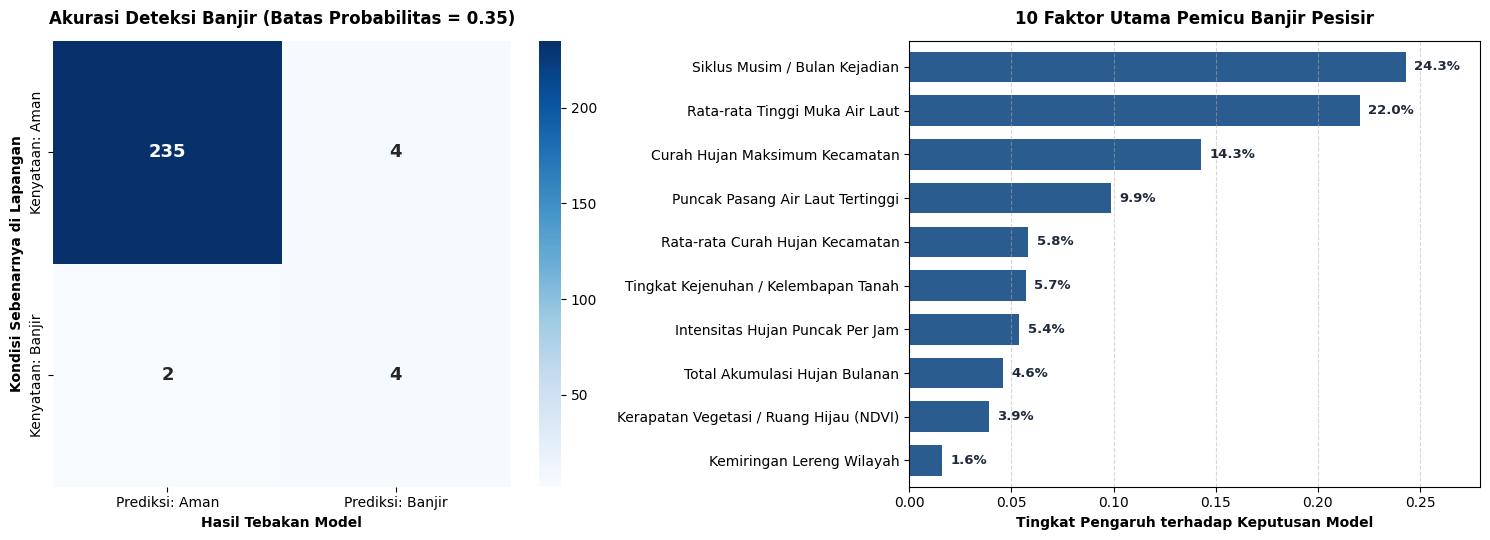

In [ ]:
# --- STAGE 1: BINARY CLASSIFICATION (DETEKSI BANJIR) ---
model_stage1 = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight='balanced',
    random_state=42
)
model_stage1.fit(X_train, y_train)

# Prediksi probabilitas dan kelas pada data uji
y_prob = model_stage1.predict_proba(X_test)[:, 1]
threshold = 0.35
y_pred = (y_prob >= threshold).astype(int)

print("=== EVALUASI STAGE 1: DETEKSI KEJADIAN BANJIR (DATA UJI) ===")
print(classification_report(y_test, y_pred, target_names=['Aman (0)', 'Banjir (1)']))
print(f"PR-AUC Score: {average_precision_score(y_test, y_prob):.4f}")

# --- STAGE 2: IDENTIFIKASI PEMICU BANJIR (RULE-BASED) ---
hasil_test = df_coastal.loc[X_test.index, ['kecamatan', 'year', 'month', 'rain_index', 'sea_index']].copy()
hasil_test['Aktual_Banjir'] = y_test
hasil_test['Prediksi_Banjir'] = y_pred
hasil_test['Probabilitas_Banjir'] = np.round(y_prob, 3)

def tentukan_pemicu(row):
    if row['Prediksi_Banjir'] == 0:
        return '0 - Aman'
    elif row['rain_index'] > 0.5 and row['sea_index'] > 0.5:
        return '3 - Compound Flood'
    elif row['sea_index'] > 0.5:
        return '2 - Banjir Rob'
    else:
        return '1 - Hujan Lokal'

hasil_test['Prediksi_Skenario'] = hasil_test.apply(tentukan_pemicu, axis=1)

print("\n=== CONTOH HASIL PREDIKSI TWO-STAGE PADA KASUS TERDETEKSI BANJIR ===")
display(hasil_test[hasil_test['Prediksi_Banjir'] == 1].head(10))

# --- KAMUS PENERJEMAH NAMA FITUR KE BAHASA MANUSIA ---
label_manusia = {
    'month': 'Siklus Musim / Bulan Kejadian',
    'sea_level_mean': 'Rata-rata Tinggi Muka Air Laut',
    'max_rainfall': 'Curah Hujan Maksimum Kecamatan',
    'sea_level_max': 'Puncak Pasang Air Laut Tertinggi',
    'avg_rainfall': 'Rata-rata Curah Hujan Kecamatan',
    'soil_moisture': 'Tingkat Kejenuhan / Kelembapan Tanah',
    'weather_rain_max': 'Intensitas Hujan Puncak Per Jam',
    'weather_rain_sum': 'Total Akumulasi Hujan Bulanan',
    'ndvi': 'Kerapatan Vegetasi / Ruang Hijau (NDVI)',
    'slope': 'Kemiringan Lereng Wilayah',
    'elevation': 'Ketinggian Daratan dari Permukaan Laut',
    'weather_temp_max': 'Suhu Udara Maksimum'
}

# --- VISUALISASI CONFUSION MATRIX & FEATURE IMPORTANCE ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Confusion Matrix dengan label yang lebih informatif
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], annot_kws={"size": 13, "weight": "bold"},
            xticklabels=['Prediksi: Aman', 'Prediksi: Banjir'],
            yticklabels=['Kenyataan: Aman', 'Kenyataan: Banjir'])
axes[0].set_title(f'Akurasi Deteksi Banjir (Batas Probabilitas = {threshold})', fontweight='bold', pad=12)
axes[0].set_ylabel('Kondisi Sebenarnya di Lapangan', fontweight='bold')
axes[0].set_xlabel('Hasil Tebakan Model', fontweight='bold')

# Plot 2: Top 10 Feature Importance dengan nama fitur yang sudah diterjemahkan
importances = pd.Series(model_stage1.feature_importances_, index=features)
# Ganti nama teknis menjadi label bahasa manusia (jika ada di kamus)
importances.index = [label_manusia.get(col, col.replace('landcover_class_', 'Tutupan Lahan: ')) for col in importances.index]
top10_importances = importances.sort_values(ascending=True).tail(10)

bars = top10_importances.plot(kind='barh', color='#2b5c8f', ax=axes[1], width=0.7)
axes[1].set_title('10 Faktor Utama Pemicu Banjir Pesisir', fontweight='bold', pad=12)
axes[1].set_xlabel('Tingkat Pengaruh terhadap Keputusan Model', fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# Menambahkan angka persentase pengaruh di ujung setiap batang grafik
for bar in bars.patches:
    width = bar.get_width()
    axes[1].text(width + 0.004, bar.get_y() + bar.get_height()/2,
                 f'{width*100:.1f}%', va='center', ha='left', fontsize=9.5, color='#1e293b', fontweight='bold')

# Memberi ruang ekstra di sisi kanan grafik agar angka persentase tidak terpotong
axes[1].set_xlim(0, top10_importances.max() * 1.15)

plt.tight_layout()
plt.show()

### 📊 Pembahasan Hasil Evaluasi & Insight Model

#### 1. Evaluasi Performa Prediksi (*Confusion Matrix*)
Pada pengujian terhadap **245 sampel wilayah pesisir** dengan ambang batas probabilitas (*threshold*) **0.35**, model menunjukkan kinerja yang seimbang antara ketepatan prediksi kondisi normal dan sensitivitas deteksi banjir:
* **Deteksi Kondisi Aman (*True Negative* = 235 dari 239):** Model mampu mengenali kondisi aman dengan akurasi **98,3%**, sehingga tidak menimbulkan kepanikan akibat terlalu banyak peringatan palsu (*False Positive* hanya 4 kasus).
* **Sensitivitas Deteksi Banjir (*Recall* = 66,7%):** Model berhasil mendeteksi **4 dari 6 kejadian banjir aktual** pada data uji, dengan **Precision sebesar 50%** (4 prediksi tepat dari 8 peringatan banjir yang dikeluarkan).
* **Analisis *False Positive* (Kasus Kecamatan Kemiri, Jan 2023):** Salah satu dari 4 peringatan dini yang tercatat sebagai *False Positive* terjadi pada kondisi indeks hujan (`1.09`) dan indeks pasang laut (`1.05`) yang sama-sama ekstrem. Secara fisik, model menangkap potensi ancaman *Compound Flood* yang nyata meskipun pada bulan tersebut tidak tercatat laporan genangan.

#### 2. Insight Faktor Pemicu Utama (*Feature Importance*)
Berdasarkan nilai *Gini Importance*, pola banjir pesisir di Jakarta Utara, Tangerang, dan Bekasi dikendalikan oleh interaksi tiga faktor utama:
1. **Pola Musiman & Tinggi Muka Air Laut (`month` & `sea_level_mean`):** Menjadi prediktor paling dominan (bobot > 0.20), menegaskan bahwa kerentanan banjir pesisir sangat terpusat pada periode puncak musim monsun dan pasang laut bulanan (terutama bulan Januari).
2. **Ekstrem Hujan Lokal & Pasang Puncak (`max_rainfall` & `sea_level_max`):** Curah hujan maksimum di tingkat kecamatan jauh lebih menentukan dibandingkan rata-rata hujan bulanan, karena hujan lebat berdurasi singkat yang bersamaan dengan pasang puncak langsung melumpuhkan sistem drainase pesisir.
3. **Kondisi Kejenuhan Tanah (`soil_moisture`):** Kelembapan tanah berperan sebagai faktor pendukung yang mengurangi kapasitas infiltrasi air hujan ke dalam tanah.

## 🌊 Ringkasan Hasil & Temuan Utama Prediksi Banjir Pesisir

> 💡 **Kesimpulan Utama:** Banjir di wilayah pesisir tidak hanya dipicu oleh curah hujan tinggi, melainkan terjadi ketika **puncak musim hujan bertepatan dengan pasang maksimum air laut** serta kondisi tanah yang sudah jenuh air, sehingga aliran drainase darat ke laut terhambat.

---

### 🎯 1. Evaluasi Performa Prediksi Model
Pengujian dilakukan pada **245 sampel wilayah pesisir** (elevasi $\le 15$ mdpl) yang belum pernah dipelajari model sebelumnya, dengan batas sensitivitas peringatan dini pada probabilitas **35% (`0.35`)**:

| Kondisi Aktual di Lapangan | Hasil Prediksi Model | Tingkat Akurasi | Interpretasi Hasil |
| :--- | :--- | :---: | :--- |
| **Aman** (239 kejadian) | **235 tepat Aman** *(4 peringatan dini)* | **98,3%** | Model sangat stabil dalam mengenali kondisi normal dan meminimalkan peringatan palsu (*false alarm*). |
| **Banjir** (6 kejadian) | **4 tepat Banjir** *(2 tidak terdeteksi)* | **66,7%** | Model mampu mendeteksi mayoritas kejadian banjir secara efektif sebagai sistem peringatan dini. |

> 🔍 **Analisis Kasus Peringatan Dini (Kecamatan Kemiri, Januari 2023):** Salah satu peringatan dini yang dikeluarkan model memiliki tingkat keyakinan **59,6%** dengan kategori ***Compound Flood***[cite: 1, 2, 3]. Berdasarkan data historis, indeks curah hujan (`1.09`) dan tinggi pasang laut (`1.05`) pada bulan tersebut memang berada pada level ekstrem, sehingga peringatan model tetap relevan secara hidrologis sebagai langkah antisipasi[cite: 1].

---

### 🏆 2. Faktor Utama Pemicu Banjir Pesisir
Berdasarkan bobot pembelajaran algoritma *Random Forest* terhadap 14 variabel lingkungan, terdapat **tiga kelompok faktor utama** yang paling memengaruhi terjadinya banjir:

* 🗓️ **Siklus Musim & Tinggi Muka Air Laut (Kontribusi 46,3%):**
  **Siklus Bulan Kejadian (24,3%)** dan **Rata-rata Tinggi Muka Air Laut (22,0%)** menjadi faktor paling dominan[cite: 2, 3]. Hal ini menunjukkan bahwa kerentanan banjir pesisir terpusat pada periode puncak musim hujan yang bersamaan dengan siklus pasang laut bulanan.
* 🌧️ **Intensitas Hujan Ekstrem & Puncak Pasang (Kontribusi 24,2%):**
  **Curah Hujan Maksimum Kecamatan (14,3%)** dan **Puncak Pasang Air Laut Tertinggi (9,9%)** berpengaruh jauh lebih besar dibandingkan hujan harian biasa, karena hujan lebat berdurasi singkat saat laut pasang langsung menghambat pembuangan air ke laut[cite: 2, 3].
* 🌱 **Kondisi Tanah & Tutupan Vegetasi (Kontribusi 9,6%):**
  **Tingkat Kejenuhan Tanah (5,7%)** dan **Kerapatan Vegetasi / Ruang Hijau (3,9%)** berperan sebagai faktor penguat; tanah yang sudah jenuh air dan minim ruang hijau akan mempercepat terjadinya genangan di permukaan[cite: 2, 3].

---

### 🛡️ 3. Rekomendasi Mitigasi Berbasis Data
1. **Integrasi Sistem Peringatan Dini:** Pemantauan risiko banjir di wilayah pesisir perlu menggabungkan prakiraan **curah hujan ekstrem tingkat kecamatan** dengan **kalender pasang maksimum air laut**, terutama saat memasuki bulan puncak musim hujan.
2. **Optimalisasi Kesiapsiagaan Pompa Air:** Pengoperasian pintu air dan pompa pengendali banjir pesisir disarankan untuk disiagakan lebih awal ketika **indikator kejenuhan tanah mulai tinggi**, guna mencegah tertahannya aliran air saat hujan lebat dan pasang laut terjadi bersamaan.

In [ ]:
from google.colab import files
files.download('dataset_compound_flood_ready.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
from datetime import date
import duckdb
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Baca dataset (otomatis buka upload jika file belum ada di Colab)
file_name = "dataset_compound_flood_ready.csv"
if not os.path.exists(file_name):
    from google.colab import files
    print(f"File '{file_name}' belum ditemukan. Silakan pilih filenya untuk diunggah...")
    files.upload()

df = pd.read_csv(file_name)
df["kabupaten_kota"] = df["kabupaten_kota"].astype(str).str.strip().str.lower()
df["kecamatan"] = df["kecamatan"].astype(str).str.strip().str.lower()

# 2. Agregasi fitur per kecamatan (58 wilayah)
df_agg = df.groupby(["kabupaten_kota", "kecamatan"], as_index=False).agg(
    lat=("lat", "first"),
    long=("long", "first"),
    elevation=("elevation", "first"),
    slope=("slope", "first"),
    landcover_class=("landcover_class", "first"),
    avg_rainfall_mean=("avg_rainfall", "mean"),
    max_rainfall_peak=("max_rainfall", "max"),
    sea_level_max_peak=("sea_level_max", "max"),
    sea_level_mean_avg=("sea_level_mean", "mean"),
    soil_moisture_avg=("soil_moisture", "mean"),
    ndvi_avg=("ndvi", "mean"),
    rain_index_avg=("rain_index", "mean"),
    sea_index_avg=("sea_index", "mean"),
    compound_risk_avg=("compound_risk_score", "mean"),
    total_banjir=("banjir", "sum"),
)

feature_cols = [
    "elevation",
    "slope",
    "avg_rainfall_mean",
    "max_rainfall_peak",
    "sea_level_max_peak",
    "sea_level_mean_avg",
    "soil_moisture_avg",
    "ndvi_avg",
    "rain_index_avg",
    "sea_index_avg",
    "compound_risk_avg",
    "total_banjir",
]

# 3. Standarisasi & fit K-Means (k = 3)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_agg[feature_cols])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_agg["cluster_id"] = kmeans.fit_predict(X_scaled)
sil_score = silhouette_score(X_scaled, df_agg["cluster_id"])

# 4. Beri label klaster yang rapi & faktual
label_map = {
    2: "Zona Dataran Rendah & Riwayat Banjir Tinggi",
    0: "Zona Transisi / Kerentanan Sedang",
    1: "Zona Elevasi & Curah Hujan Tinggi",
}
df_agg["cluster_label"] = df_agg["cluster_id"].map(label_map)
df_agg["clustering_algorithm"] = "KMeans (k=3)"
df_agg["run_date"] = date.today()

print(f"Silhouette Score (k=3): {sil_score:.3f}\n")
display(
    df_agg.groupby(["cluster_id", "cluster_label"])[
        ["elevation", "slope", "avg_rainfall_mean", "ndvi_avg", "compound_risk_avg", "total_banjir"]
    ].mean().round(3)
)

# 5. Ekspor hasil berlabel ke CSV
output_csv = "cluster_wilayah_berlabel.csv"
df_agg.to_csv(output_csv, index=False)
print(f"\nTersimpan ke '{output_csv}' ({len(df_agg)} kecamatan).")

# 6. Simpan ke tabel Data Warehouse (DuckDB)
con = duckdb.connect("compound_flood_dw.duckdb")
con.execute("""
CREATE TABLE IF NOT EXISTS dim_location_vulnerability_cluster (
    kabupaten_kota VARCHAR,
    kecamatan VARCHAR,
    lat DOUBLE,
    long DOUBLE,
    elevation DOUBLE,
    slope DOUBLE,
    landcover_class VARCHAR,
    avg_rainfall_mean DOUBLE,
    max_rainfall_peak DOUBLE,
    sea_level_max_peak DOUBLE,
    sea_level_mean_avg DOUBLE,
    soil_moisture_avg DOUBLE,
    ndvi_avg DOUBLE,
    rain_index_avg DOUBLE,
    sea_index_avg DOUBLE,
    compound_risk_avg DOUBLE,
    total_banjir DOUBLE,
    cluster_id INTEGER,
    cluster_label VARCHAR,
    clustering_algorithm VARCHAR,
    run_date DATE
);
""")
con.register("tmp_cluster_df", df_agg)
con.execute("DELETE FROM dim_location_vulnerability_cluster WHERE run_date = CURRENT_DATE;")
con.execute("INSERT INTO dim_location_vulnerability_cluster SELECT * FROM tmp_cluster_df;")
con.close()
print("Berhasil dimuat ke tabel 'dim_location_vulnerability_cluster' di compound_flood_dw.duckdb.")

Silhouette Score (k=3): 0.281



,,elevation,slope,avg_rainfall_mean,ndvi_avg,compound_risk_avg,total_banjir
cluster_id,cluster_label,,,,,,
0,Zona Transisi / Kerentanan Sedang,16.004,0.125,30.866,0.436,0.698,0.522
1,Zona Elevasi & Curah Hujan Tinggi,42.604,0.283,37.732,0.546,0.768,0.333
2,Zona Dataran Rendah & Riwayat Banjir Tinggi,6.346,0.076,25.962,0.365,0.678,1.261



Tersimpan ke 'cluster_wilayah_berlabel.csv' (58 kecamatan).
Berhasil dimuat ke tabel 'dim_location_vulnerability_cluster' di compound_flood_dw.duckdb.


In [ ]:
import pandas as pd

# 1. Baca data bulanan & hasil clustering wilayah
df_obs = pd.read_csv("dataset_compound_flood_ready.csv")
df_cls = pd.read_csv("cluster_wilayah_berlabel.csv")

df_obs["kabupaten_kota"] = df_obs["kabupaten_kota"].astype(str).str.strip().str.lower()
df_obs["kecamatan"] = df_obs["kecamatan"].astype(str).str.strip().str.lower()
df_cls["kabupaten_kota"] = df_cls["kabupaten_kota"].astype(str).str.strip().str.lower()
df_cls["kecamatan"] = df_cls["kecamatan"].astype(str).str.strip().str.lower()

# 2. Gabungkan (join) atribut klaster wilayah ke data observasi bulanan
cluster_cols = [
    "kabupaten_kota",
    "kecamatan",
    "cluster_id",
    "cluster_label",
    "clustering_algorithm",
]
df_dashboard = df_obs.merge(df_cls[cluster_cols], on=["kabupaten_kota", "kecamatan"], how="left")

# 3. Simpan dataset gabungan siap visualisasi dashboard
dashboard_csv = "dashboard_compound_flood_enriched.csv"
df_dashboard.to_csv(dashboard_csv, index=False)
print(f"Tersimpan ke '{dashboard_csv}' -> {df_dashboard.shape[0]} baris, {df_dashboard.shape[1]} kolom")

# 4. Ringkasan per klaster untuk validasi cepat
ringkasan = (
    df_dashboard.groupby(["cluster_id", "cluster_label"])
    .agg(
        jumlah_kecamatan=("kecamatan", "nunique"),
        total_banjir=("banjir", "sum"),
        compound_flood_count=("trigger_label", lambda s: (s == 3).sum()),
        avg_compound_risk=("compound_risk_score", "mean"),
        avg_elevation=("elevation", "mean"),
        avg_ndvi=("ndvi", "mean"),
    )
    .round(3)
)
display(ringkasan)

Tersimpan ke 'dashboard_compound_flood_enriched.csv' -> 2088 baris, 36 kolom


,,jumlah_kecamatan,total_banjir,compound_flood_count,avg_compound_risk,avg_elevation,avg_ndvi
cluster_id,cluster_label,,,,,,
0,Zona Transisi / Kerentanan Sedang,23,12,10,0.698,16.004,0.436
1,Zona Elevasi & Curah Hujan Tinggi,12,4,4,0.768,42.604,0.546
2,Zona Dataran Rendah & Riwayat Banjir Tinggi,23,29,26,0.678,6.346,0.365


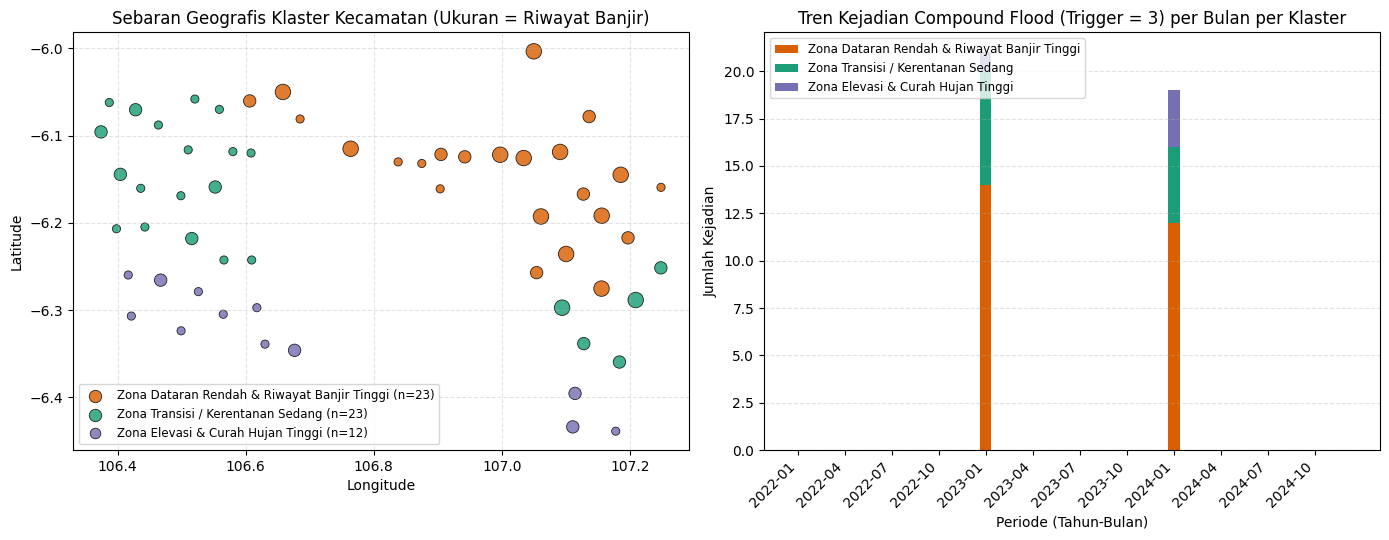

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_dash = pd.read_csv("dashboard_compound_flood_enriched.csv")
df_dash["ym"] = (
    df_dash["year"].astype(str) + "-" + df_dash["month"].astype(str).str.zfill(2)
)

# Ringkasan per kecamatan untuk plot spasial
kec_summary = df_dash.groupby(
    ["kabupaten_kota", "kecamatan", "cluster_id", "cluster_label"], as_index=False
).agg(
    lat=("lat", "first"),
    long=("long", "first"),
    total_banjir=("banjir", "sum"),
    compound_flood_count=("trigger_label", lambda s: (s == 3).sum()),
)

# Tren bulanan kejadian Compound Flood (trigger_label == 3)
all_ym = sorted(df_dash["ym"].unique().tolist())
cf_monthly = (
    df_dash[df_dash["trigger_label"] == 3]
    .groupby(["ym", "cluster_label"])
    .size()
    .unstack(fill_value=0)
    .reindex(all_ym, fill_value=0)
)

colors_map = {
    "Zona Dataran Rendah & Riwayat Banjir Tinggi": "#d95f02",
    "Zona Transisi / Kerentanan Sedang": "#1b9e77",
    "Zona Elevasi & Curah Hujan Tinggi": "#7570b3",
}
cluster_order = [
    "Zona Dataran Rendah & Riwayat Banjir Tinggi",
    "Zona Transisi / Kerentanan Sedang",
    "Zona Elevasi & Curah Hujan Tinggi",
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel kiri: sebaran koordinat kecamatan & ukuran titik berdasarkan riwayat banjir
for lbl in cluster_order:
    grp = kec_summary[kec_summary["cluster_label"] == lbl]
    axes[0].scatter(
        grp["long"],
        grp["lat"],
        s=np.clip(grp["total_banjir"] * 45 + 35, 35, 220),
        c=colors_map[lbl],
        alpha=0.82,
        edgecolors="black",
        linewidth=0.6,
        label=f"{lbl} (n={len(grp)})",
    )

axes[0].set_title("Sebaran Geografis Klaster Kecamatan (Ukuran = Riwayat Banjir)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].legend(loc="best", fontsize=8.5)
axes[0].grid(True, linestyle="--", alpha=0.35)

# Panel kanan: tren kejadian Compound Flood per bulan
x_idx = np.arange(len(all_ym))
bottom = np.zeros(len(all_ym))
for lbl in cluster_order:
    vals = cf_monthly[lbl].values if lbl in cf_monthly.columns else np.zeros(len(all_ym))
    axes[1].bar(x_idx, vals, bottom=bottom, width=0.72, color=colors_map[lbl], label=lbl)
    bottom += vals

step = 3
axes[1].set_xticks(x_idx[::step])
axes[1].set_xticklabels(
    [all_ym[i] for i in range(0, len(all_ym), step)], rotation=45, ha="right"
)
axes[1].set_title("Tren Kejadian Compound Flood (Trigger = 3) per Bulan per Klaster")
axes[1].set_xlabel("Periode (Tahun-Bulan)")
axes[1].set_ylabel("Jumlah Kejadian")
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("dashboard_klaster_spasial_tren.png", dpi=150)
plt.show()